# Customer Segmentation – Online Retail II
**Goal:** Identify customer segments based on purchasing behavior (RFM: Recency, Frequency, Monetary)
and translate them into actionable business groups.

**Business question:** *What types of customers does the store have, and which commercial action fits each one?*

**Methods:** K-Means, Agglomerative Hierarchical Clustering (Ward), DBSCAN.
**Dataset:** [Online Retail II – UCI](https://archive.ics.uci.edu/dataset/502/online+retail+ii)

In [1]:
# --- Environment setup (run once, then keep commented) ---
# %pip install pandas numpy matplotlib seaborn scikit-learn scipy openpyxl

In [2]:
# --- Imports & settings ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

In [3]:
# --- Load both sheets (sheet[2009-2010] and sheet[2010-2011]) and cache as CSV ---
RAW_XLSX  = DATA_DIR / "online_retail_II.xlsx"
CACHE_CSV = DATA_DIR / "online_retail_II.csv"

if CACHE_CSV.exists():
    df_raw = pd.read_csv(CACHE_CSV, dtype={"Invoice": str, "StockCode": str},
                         parse_dates=["InvoiceDate"])
else:
    sheets = pd.read_excel(RAW_XLSX, sheet_name=[0, 1], dtype={"Invoice": str, "StockCode": str}) #2 sheets
    print("Sheets found:", list(sheets.keys()))
    df_raw = pd.concat(sheets.values(), ignore_index=True)
    df_raw.to_csv(CACHE_CSV, index=False)

print("Shape:", df_raw.shape)
df_raw.head()

Shape: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


In [4]:
# --- Structure and descriptive statistics ---
df_raw.info()
df_raw.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  str           
 1   StockCode    1067371 non-null  str           
 2   Description  1062989 non-null  str           
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 117.3 MB


,Quantity,InvoiceDate,Price,Customer ID
count,"1,067,371.00",1067371,"1,067,371.00","824,364.00"
mean,9.94,2011-01-02 21:13:55.394029,4.65,"15,324.64"
min,"-80,995.00",2009-12-01 07:45:00,"-53,594.36","12,346.00"
25%,1.00,2010-07-09 09:46:00,1.25,"13,975.00"
50%,3.00,2010-12-07 15:28:00,2.10,"15,255.00"
75%,10.00,2011-07-22 10:23:00,4.15,"16,797.00"
max,"80,995.00",2011-12-09 12:50:00,"38,970.00","18,287.00"
std,172.71,NaN,123.55,"1,697.46"


In [5]:
# --- Data quality checks ---
n = len(df_raw)
checks = pd.Series({
    "Missing Customer ID": df_raw["Customer ID"].isna().sum(),
    "Missing Description": df_raw["Description"].isna().sum(),
    "Cancellations (Invoice starts with 'C')": df_raw["Invoice"].str.startswith("C").sum(),
    "Quantity <= 0": (df_raw["Quantity"] <= 0).sum(),
    "Price <= 0": (df_raw["Price"] <= 0).sum(),
    "Exact duplicate rows": df_raw.duplicated().sum(),
}).to_frame("count")
checks["pct_of_rows"] = (checks["count"] / n * 100).round(2)
display(checks)

print(f"Unique customers: {df_raw['Customer ID'].nunique():,}")
print(f"Unique invoices:  {df_raw['Invoice'].nunique():,}")
print(f"Unique products:  {df_raw['StockCode'].nunique():,}")
print(f"Date range: {df_raw['InvoiceDate'].min()} -> {df_raw['InvoiceDate'].max()}")

,count,pct_of_rows
Missing Customer ID,243007,22.77
Missing Description,4382,0.41
Cancellations (Invoice starts with 'C'),19494,1.83
Quantity <= 0,22950,2.15
Price <= 0,6207,0.58
Exact duplicate rows,34335,3.22


Unique customers: 5,942
Unique invoices:  53,628
Unique products:  5,305
Date range: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00


In [6]:
# --- Non-product stock codes (postage, manual adjustments, bank charges...) ---
# StockCode: a 5-digit integral number uniquely assigned to each distinct product
non_product_mask = ~df_raw["StockCode"].str.match(r"^\d{5}", na=False)
print("Rows with non-standard StockCode:", non_product_mask.sum())
df_raw.loc[non_product_mask, ["StockCode", "Description"]].value_counts().head(20)

Rows with non-standard StockCode: 6093


StockCode     Description                        
POST          POSTAGE                                2115
DOT           DOTCOM POSTAGE                         1444
M             Manual                                 1421
C2            CARRIAGE                                279
D             Discount                                177
S             SAMPLES                                 104
BANK CHARGES  Bank Charges                             96
AMAZONFEE     AMAZON FEE                               43
ADJUST        Adjustment by john on 26/01/2010 16      38
DCGS0058      MISO PRETTY  GUM                         30
gift_0001_20  Dotcomgiftshop Gift Voucher £20.00       26
ADJUST        Adjustment by john on 26/01/2010 17      26
gift_0001_30  Dotcomgiftshop Gift Voucher £30.00       24
DCGSSGIRL     GIRLS PARTY BAG                          23
DCGSSBOY      BOYS PARTY BAG                           21
PADS          PADS TO MATCH ALL CUSHIONS               19
CRUK          CRUK Com

In [7]:
# --- Top countries by number of customers ---
top_countries = (df_raw.dropna(subset=["Customer ID"])
                 .groupby("Country")["Customer ID"].nunique()
                 .sort_values(ascending=False))
display(top_countries.head(10).to_frame("customers"))
print(f"UK share of customers: {top_countries.get('United Kingdom', 0) / top_countries.sum():.1%}")

,customers
Country,
United Kingdom,5410
Germany,107
France,95
Spain,41
Belgium,29
Portugal,24
Netherlands,23
Switzerland,22
Sweden,19


UK share of customers: 90.8%


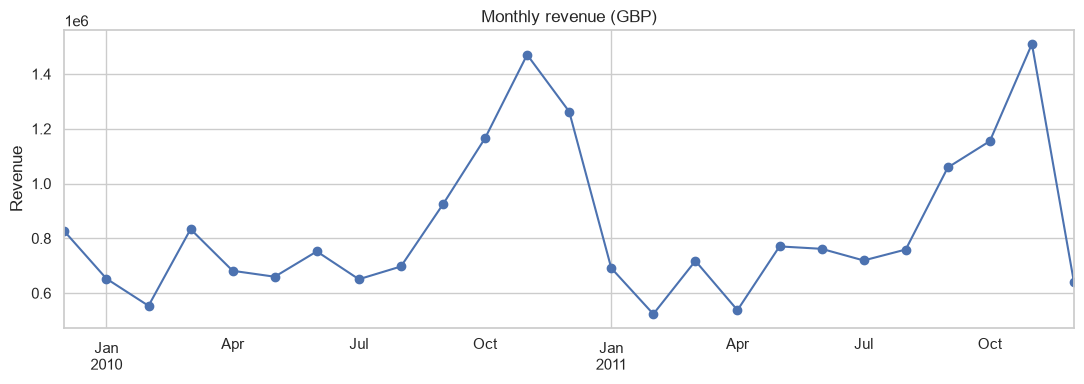

In [8]:
# --- Monthly revenue (valid sales only) ---
sales = df_raw[(df_raw["Quantity"] > 0) & (df_raw["Price"] > 0)].copy()
sales["Revenue"] = sales["Quantity"] * sales["Price"]
monthly = sales.set_index("InvoiceDate").resample("MS")["Revenue"].sum()

fig, ax = plt.subplots(figsize=(11, 4))
monthly.plot(ax=ax, marker="o")
ax.set_title("Monthly revenue (GBP)")
ax.set_xlabel(""); ax.set_ylabel("Revenue")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_monthly_revenue.png", dpi=120)
plt.show()

## 2. Data Cleaning
Cleaning rules (documented assumptions):
1. **Missing Customer ID** → removed (cannot be attributed to a customer).
2. **Cancellations** (Invoice starting with "C") → removed. *Limitation: returns are not netted against purchases.*
3. **Quantity ≤ 0 or Price ≤ 0** → removed (returns, adjustments, free items).
4. **Non-product StockCodes** → removed. Per the UCI documentation, a product StockCode is a 5-digit number
   (optionally followed by a letter for variants). Other codes (POST, M, BANK CHARGES, AMAZONFEE...) are fees or adjustments, not merchandise.
5. **Exact duplicate rows** → removed.

All countries are kept: Country is not an RFM feature, and the UK represents ~91% of customers.

In [9]:
# --- Cleaning pipeline (logs rows remaining after each step) ---
df = df_raw.copy()
log = [("Raw data", len(df))]

df = df.dropna(subset=["Customer ID"])
log.append(("Drop missing Customer ID", len(df)))

df = df[~df["Invoice"].str.startswith("C")]
log.append(("Drop cancellations", len(df)))

df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]
log.append(("Drop Quantity/Price <= 0", len(df)))

df = df[df["StockCode"].str.match(r"^\d{5}", na=False)]
log.append(("Drop non-product StockCodes", len(df)))

df = df.drop_duplicates()
log.append(("Drop exact duplicates", len(df)))

df["Customer ID"] = df["Customer ID"].astype(int)
df["Revenue"] = df["Quantity"] * df["Price"]

cleaning_log = pd.DataFrame(log, columns=["step", "rows_remaining"])
cleaning_log["rows_removed"] = (-cleaning_log["rows_remaining"].diff()).fillna(0).astype(int)
cleaning_log["pct_of_raw"] = (cleaning_log["rows_remaining"] / len(df_raw) * 100).round(2)
display(cleaning_log)
print(f"Customers after cleaning: {df['Customer ID'].nunique():,}")

,step,rows_remaining,rows_removed,pct_of_raw
0,Raw data,1067371,0,100.00
1,Drop missing Customer ID,824364,243007,77.23
2,Drop cancellations,805620,18744,75.48
3,Drop Quantity/Price <= 0,805549,71,75.47
4,Drop non-product StockCodes,802632,2917,75.20
5,Drop exact duplicates,776577,26055,72.76


Customers after cleaning: 5,852


In [10]:
# --- Cancellations: kept separately to net them out of Monetary ---
cancels = df_raw[
    df_raw["Invoice"].str.startswith("C")
    & df_raw["Customer ID"].notna()
    & df_raw["StockCode"].str.match(r"^\d{5}", na=False)
    & (df_raw["Quantity"] < 0)
].drop_duplicates().copy()
cancels["Customer ID"] = cancels["Customer ID"].astype(int)
cancels["Revenue"] = cancels["Quantity"] * cancels["Price"]      # negative values

print(f"Cancellation rows: {len(cancels):,}")
print(f"Cancelled revenue: £{cancels['Revenue'].sum():,.2f}")
print(f"Customers with cancellations: {cancels['Customer ID'].nunique():,}")

Cancellation rows: 17,586
Cancelled revenue: £-709,953.43
Customers with cancellations: 2,444


## 3. RFM Feature Engineering
- **Recency**: days since the customer's last purchase, measured from a reference date (last date in the dataset + 1 day).
- **Frequency**: number of distinct invoices (purchase orders).
- **Monetary**: **net** revenue (Quantity × Price of purchases minus cancelled orders).

In [11]:
# --- Build RFM table (one row per customer) ---
reference_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
print("Reference date:", reference_date.date())

rfm = df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
)

# --- Net Monetary = purchases + cancellations (negative values) ---
cancel_by_cust = cancels.groupby("Customer ID")["Revenue"].sum()
rfm["Monetary"] = (rfm["Monetary"] + cancel_by_cust.reindex(rfm.index, fill_value=0)).round(2)

n_before = len(rfm)
rfm = rfm[rfm["Monetary"] > 0]
print(f"Customers removed (net Monetary <= 0): {n_before - len(rfm)}")

print("RFM shape:", rfm.shape)
display(rfm.head())
display(rfm.describe(percentiles=[.25, .5, .75, .95, .99]))
print("Skewness:\n", rfm.skew().round(2))

Reference date: 2011-12-10
Customers removed (net Monetary <= 0): 20
RFM shape: (5832, 3)


,Recency,Frequency,Monetary
Customer ID,,,
12346,325,3,169.36
12347,2,8,"4,921.53"
12348,75,5,"1,658.40"
12349,18,3,"3,654.54"
12350,310,1,294.40


,Recency,Frequency,Monetary
count,"5,832.00","5,832.00","5,832.00"
mean,199.38,6.27,"2,805.48"
std,208.38,12.77,"13,847.91"
min,0.00,1.00,2.90
25%,25.00,1.00,333.79
50%,95.00,3.00,843.74
75%,378.00,7.00,"2,179.89"
95%,623.00,20.00,"8,928.42"
99%,725.69,46.00,"26,543.84"
max,738.00,373.00,"578,408.64"


Skewness:
 Recency      0.90
Frequency   12.03
Monetary    26.78
dtype: float64


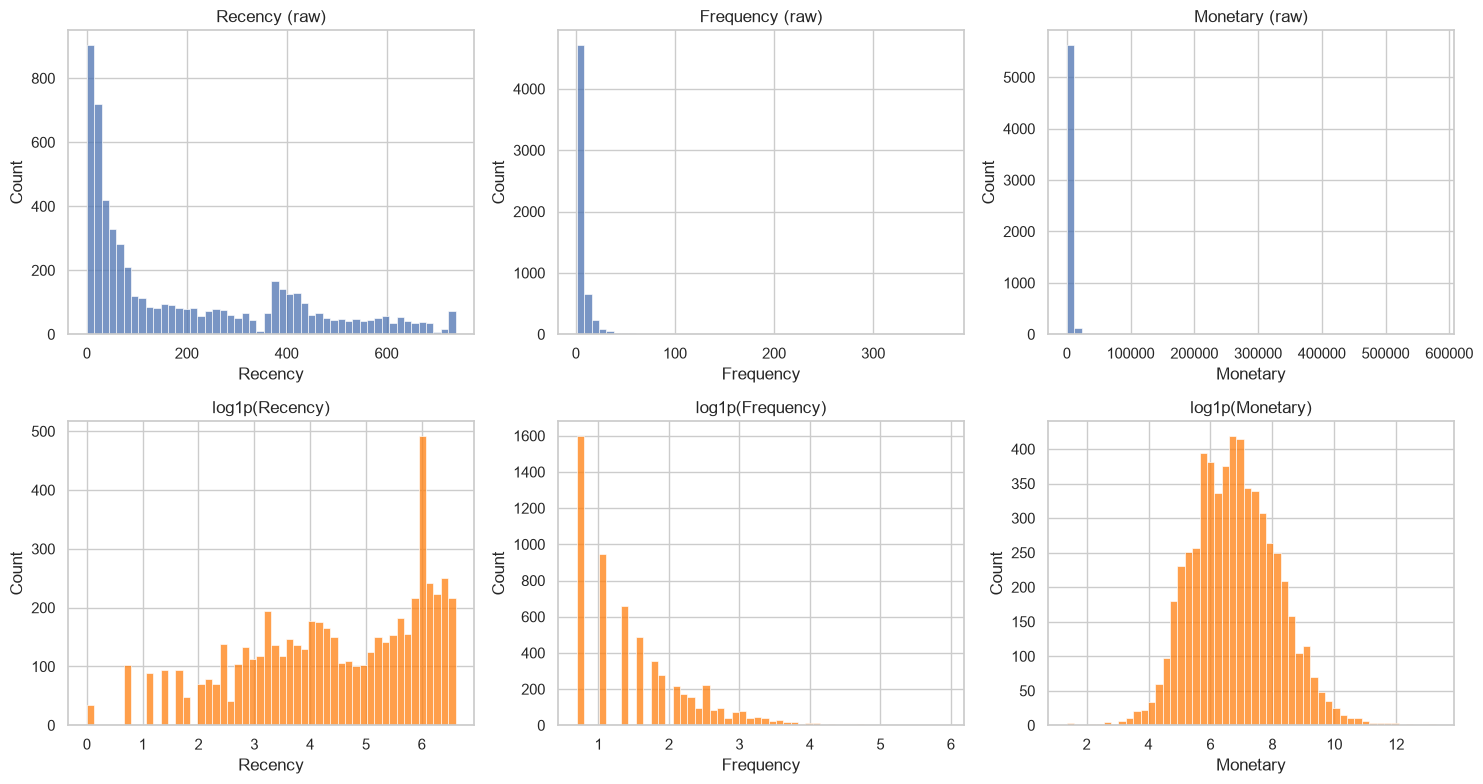

In [12]:
# --- Distributions: raw vs log-transformed ---
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[col], bins=50, ax=axes[0, i])
    axes[0, i].set_title(f"{col} (raw)")
    sns.histplot(np.log1p(rfm[col]), bins=50, ax=axes[1, i], color="tab:orange")
    axes[1, i].set_title(f"log1p({col})")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_rfm_distributions.png", dpi=120)
plt.show()

In [13]:
# --- Extreme customers (potential outliers) ---
display(rfm.sort_values("Monetary", ascending=False).head(10))
display(rfm.sort_values("Frequency", ascending=False).head(10))

,Recency,Frequency,Monetary
Customer ID,,,
18102,0,145,"578,408.64"
14646,1,145,"523,202.74"
14156,9,144,"297,775.01"
14911,1,373,"258,522.43"
17450,8,51,"233,643.91"
13694,3,143,"190,391.50"
17511,2,60,"168,504.44"
12415,24,24,"143,107.02"
16684,4,55,"141,530.29"


,Recency,Frequency,Monetary
Customer ID,,,
14911,1,373,"258,522.43"
12748,0,322,"46,671.23"
17841,1,211,"67,275.26"
15311,0,207,"111,444.36"
13089,2,203,"109,893.24"
14606,1,184,"28,913.22"
17850,372,155,"50,407.77"
14646,1,145,"523,202.74"
18102,0,145,"578,408.64"


In [14]:
# --- Log transform + standard scaling (input for clustering) ---
from sklearn.preprocessing import StandardScaler

rfm_log = np.log1p(rfm)
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(rfm_log),
                        index=rfm.index, columns=rfm.columns)
display(X_scaled.describe().round(2))   # mean ≈ 0, std ≈ 1

rfm.to_csv(DATA_DIR / "rfm.csv")        # saved for reuse

,Recency,Frequency,Monetary
count,"5,832.00","5,832.00","5,832.00"
mean,0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-2.77,-1.06,-3.95
25%,-0.73,-1.06,-0.71
50%,0.09,-0.20,-0.04
75%,0.95,0.66,0.65
max,1.37,5.42,4.71


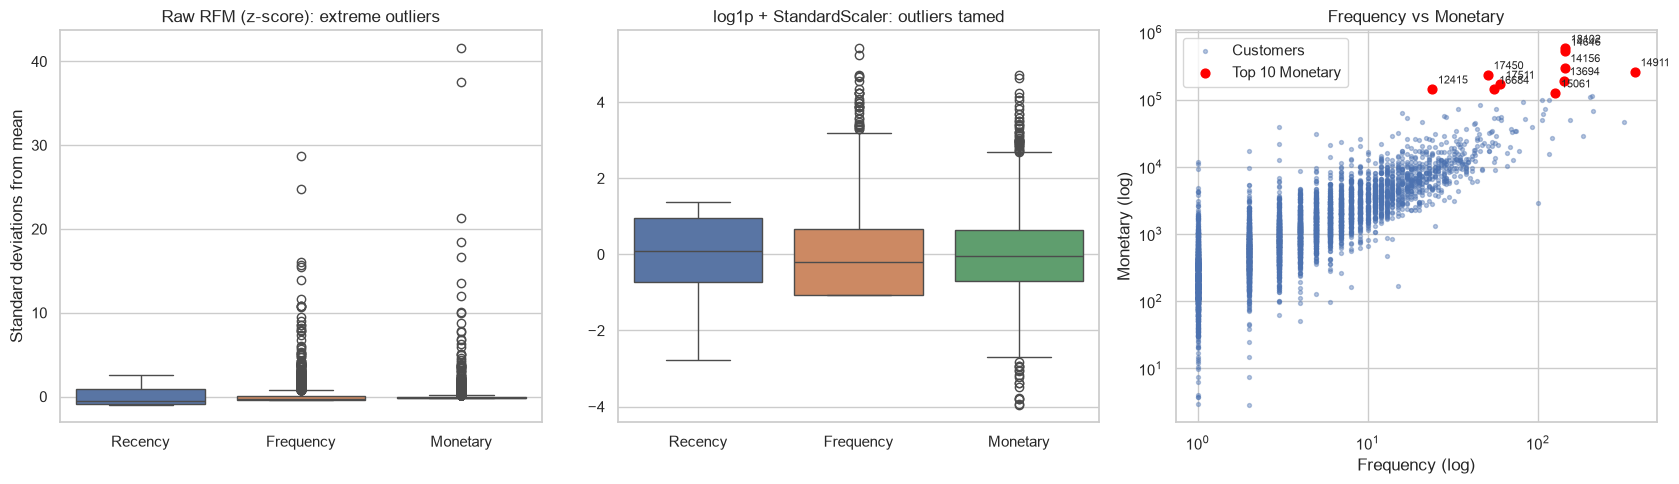

,raw,log1p,raw_pct
Recency,0,0,0.00
Frequency,424,32,7.30
Monetary,616,56,10.60


In [15]:
# --- Visualizing outliers: boxplots (raw vs log) + Frequency vs Monetary scatter ---
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 1) Boxplots on raw scale (standardized so the 3 variables share an axis)
raw_z = (rfm - rfm.mean()) / rfm.std()
sns.boxplot(data=raw_z, ax=axes[0])
axes[0].set_title("Raw RFM (z-score): extreme outliers")
axes[0].set_ylabel("Standard deviations from mean")

# 2) Boxplots after log1p + scaling (what the models will actually see)
sns.boxplot(data=X_scaled, ax=axes[1])
axes[1].set_title("log1p + StandardScaler: outliers tamed")

# 3) Frequency vs Monetary (log-log), top 10 Monetary customers highlighted
top10 = rfm.nlargest(10, "Monetary")
axes[2].scatter(rfm["Frequency"], rfm["Monetary"], s=8, alpha=0.4, label="Customers")
axes[2].scatter(top10["Frequency"], top10["Monetary"], s=40, color="red", label="Top 10 Monetary")
for cid, row in top10.iterrows():
    axes[2].annotate(str(cid), (row["Frequency"], row["Monetary"]),
                     fontsize=8, xytext=(4, 4), textcoords="offset points")
axes[2].set_xscale("log"); axes[2].set_yscale("log")
axes[2].set_xlabel("Frequency (log)"); axes[2].set_ylabel("Monetary (log)")
axes[2].set_title("Frequency vs Monetary")
axes[2].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "02b_outliers.png", dpi=120)
plt.show()

# --- Count outliers with the IQR rule (raw vs log scale) ---
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

outlier_counts = pd.DataFrame({
    "raw": rfm.apply(iqr_outliers),
    "log1p": rfm_log.apply(iqr_outliers),
})
outlier_counts["raw_pct"] = (outlier_counts["raw"] / len(rfm) * 100).round(1)
display(outlier_counts)

## 4. Baseline: Rule-based RFM Segmentation

### Why a baseline?
In supervised learning, a model is compared against a naive benchmark (e.g., always predicting the mean).
In unsupervised learning there is no accuracy to measure, so the natural benchmark is **the segmentation a marketing analyst
would build by hand using simple rules**. The question for the rest of the project becomes:

> *Does clustering find structure that simple business rules cannot see?*

### Step 1 – Score each customer from 1 to 5 (quintiles)
Customers are ranked on each RFM variable and split into **five equal-sized groups** (`pd.qcut`):

| Score | Recency | Frequency | Monetary |
|:---:|---|---|---|
| **5** | Top 20% most recent buyers | Top 20% most frequent buyers | Top 20% highest spenders |
| **1** | Bottom 20% (longest since last purchase) | Bottom 20% least frequent | Bottom 20% lowest spenders |

Notes:
- **Recency is inverted** (labels 5→1): fewer days since the last purchase is *better*.
- **Frequency uses `rank(method="first")`**: many customers have exactly 1 or 2 purchases, and these ties
  prevent `qcut` from creating 5 equal bins. Ranking breaks the ties by order of appearance.

*Example:* a customer who bought 10 days ago, with 25 invoices and £8,000 spent → **R=5, F=5, M=5**.

### Step 2 – Map R and F scores to business segments
R and F scores are combined into a two-digit code (e.g., R=5, F=4 → `"54"`) and assigned a name using the
**standard RFM segment map** widely used in CRM and marketing analytics:

| Segment | R score | F score | Interpretation |
|---|:---:|:---:|---|
| **Champions** | 5 | 4–5 | Bought recently, buy often. Best customers. |
| **Loyal Customers** | 3–4 | 4–5 | Buy regularly; responsive to loyalty programs. |
| **Potential Loyalists** | 4–5 | 2–3 | Recent customers with growing frequency. |
| **New Customers** | 5 | 1 | Bought very recently, only once. |
| **Promising** | 4 | 1 | Recent first-time buyers, slightly older. |
| **Need Attention** | 3 | 3 | Average on both; may drift away without engagement. |
| **About to Sleep** | 3 | 1–2 | Below average and cooling down. |
| **At Risk** | 1–2 | 3–4 | Used to buy often, but not for a long time. |
| **Can't Lose Them** | 1–2 | 5 | Were top buyers, now inactive. High priority for win-back. |
| **Hibernating** | 1–2 | 1–2 | Low frequency, long inactive. Likely lost. |

**Why only R and F?** Monetary is strongly correlated with Frequency (customers who buy more often tend to spend more),
so the map is kept two-dimensional for readability. M is still reported in the summary table.

### Step 3 – How to read the results
For each segment we report its size, median R/F/M and, most importantly,
**% of customers vs % of revenue**. A Pareto pattern is expected: a small share of customers (Champions, Loyal)
generating a large share of revenue.

### Limitations of the baseline (what clustering could improve)
1. **Arbitrary thresholds**: quintile cuts are fixed, not learned from the data's natural structure.
2. **Forced equal-sized bins**: each score holds 20% of customers, even if real groups are uneven.
3. **Monetary is ignored** when assigning segments.
4. **Predefined labels**: the rules can only confirm known segments; they cannot *discover* new ones.

In the following sections, clusters from K-Means and Hierarchical Clustering will be cross-tabulated against these
baseline segments (`pd.crosstab`):
- **High agreement** → the clustering *validates* that these groups genuinely exist in the data.
- **Disagreement** (a cluster merging or splitting segments) → the model reveals structure the rules miss,
  which is the **added value** of the unsupervised approach.

,customers,recency_median,frequency_median,monetary_median,revenue_total,pct_customers,pct_revenue
Segment,,,,,,,
Champions,849,8.00,11.00,"3,836.26","8,651,721.80",14.60,52.90
Loyal Customers,1124,53.00,8.00,"2,443.61","4,446,007.54",19.30,27.20
At Risk,754,374.00,4.00,921.53,"958,703.87",12.90,5.90
Potential Loyalists,715,23.00,3.00,669.91,"629,066.34",12.30,3.80
Hibernating,1507,432.00,1.00,268.28,"610,049.26",25.80,3.70
Can't Lose Them,72,314.50,11.00,"3,396.98","478,664.45",1.20,2.90
Need Attention,266,106.00,3.00,922.59,"332,479.37",4.60,2.00
About to Sleep,377,92.00,1.00,358.00,"200,262.54",6.50,1.20
Promising,112,38.00,1.00,221.62,"35,350.18",1.90,0.20


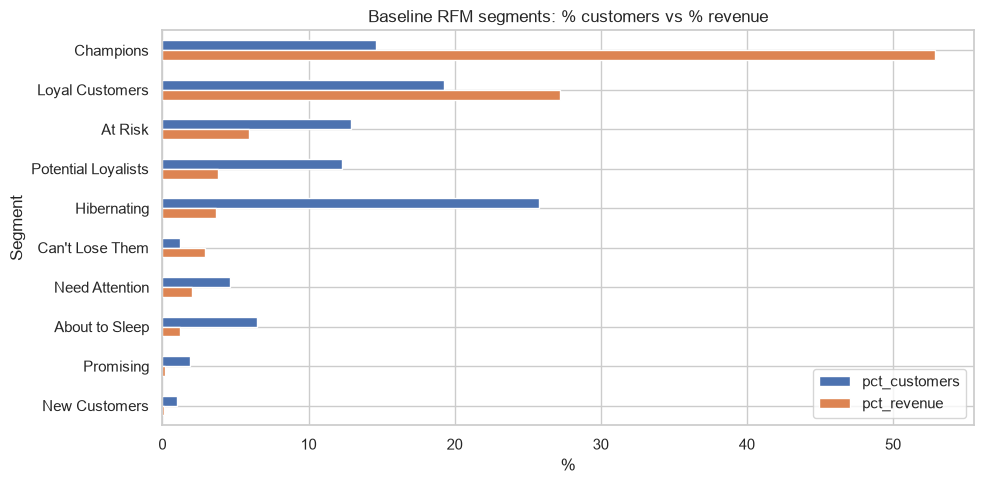

In [16]:
# --- Baseline: RFM quintile scores + standard segment map ---
base = rfm.copy()
base["R_score"] = pd.qcut(base["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)          # lower recency = better
base["F_score"] = pd.qcut(base["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
base["M_score"] = pd.qcut(base["Monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

seg_map = {
    r"^[1-2][1-2]$": "Hibernating",
    r"^[1-2][3-4]$": "At Risk",
    r"^[1-2]5$":     "Can't Lose Them",
    r"^3[1-2]$":     "About to Sleep",
    r"^33$":         "Need Attention",
    r"^[3-4][4-5]$": "Loyal Customers",
    r"^41$":         "Promising",
    r"^51$":         "New Customers",
    r"^[4-5][2-3]$": "Potential Loyalists",
    r"^5[4-5]$":     "Champions",
}
base["RF"] = base["R_score"].astype(str) + base["F_score"].astype(str)
base["Segment"] = base["RF"].replace(seg_map, regex=True)

baseline_summary = (base.groupby("Segment")
                    .agg(customers=("Recency", "size"),
                         recency_median=("Recency", "median"),
                         frequency_median=("Frequency", "median"),
                         monetary_median=("Monetary", "median"),
                         revenue_total=("Monetary", "sum"))
                    .sort_values("revenue_total", ascending=False))
baseline_summary["pct_customers"] = (baseline_summary["customers"] / len(base) * 100).round(1)
baseline_summary["pct_revenue"] = (baseline_summary["revenue_total"] / base["Monetary"].sum() * 100).round(1)
display(baseline_summary)

fig, ax = plt.subplots(figsize=(10, 5))
baseline_summary[["pct_customers", "pct_revenue"]].plot.barh(ax=ax)
ax.set_title("Baseline RFM segments: % customers vs % revenue")
ax.set_xlabel("%"); ax.invert_yaxis()
plt.tight_layout()
plt.savefig(FIG_DIR / "03_baseline_segments.png", dpi=120)
plt.show()

## 5. Choosing k – Hierarchical Clustering (Ward)

**Agglomerative clustering** starts with every customer as its own cluster and repeatedly merges the two closest clusters
until only one remains. **Ward linkage** merges the pair of clusters that produces the *smallest increase in within-cluster
variance*, the same objective K-Means minimizes, which makes both methods directly comparable.

The **dendrogram** shows this merge history: the vertical axis is the merge distance. **Long vertical lines with no merges**
indicate well-separated groups. Cutting the tree across the largest gap gives a data-driven estimate of *k*.
We then cross-check this *k* with the **Elbow method** and **Silhouette score**.

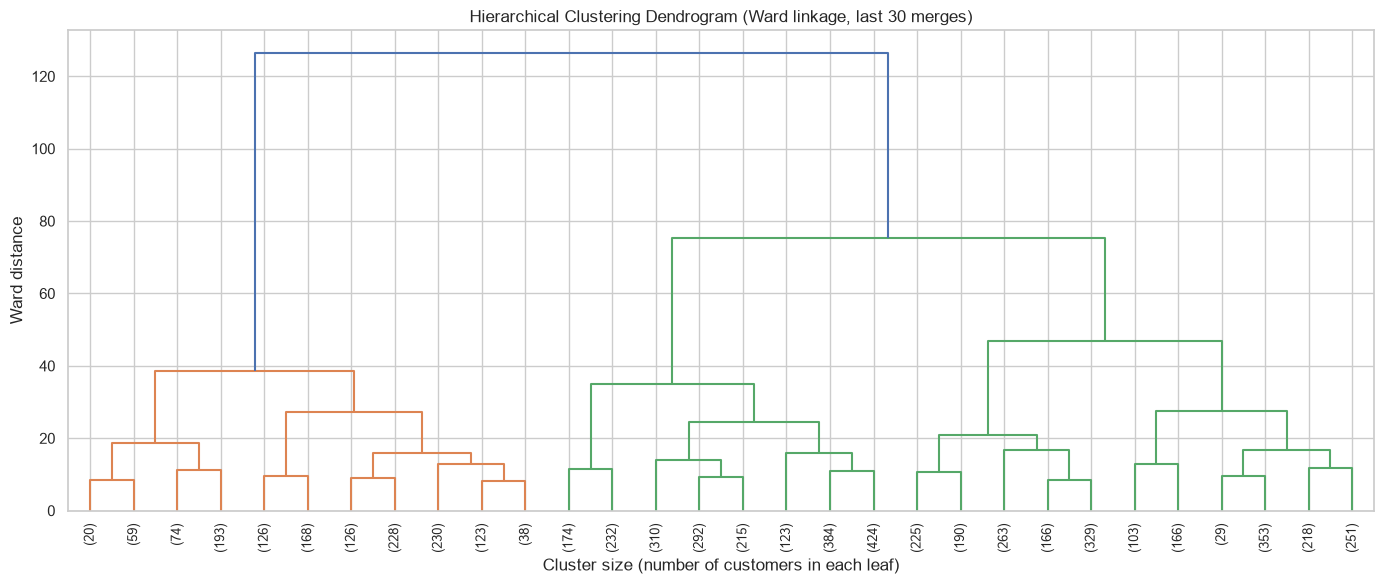

In [17]:
# --- Hierarchical clustering (Ward) and dendrogram ---
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

Z = linkage(X_scaled.values, method="ward")   # Build hierarchical clustering using Ward's method

fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True,
           leaf_rotation=90, leaf_font_size=9, ax=ax)
ax.set_title("Hierarchical Clustering Dendrogram (Ward linkage, last 30 merges)")
ax.set_xlabel("Cluster size (number of customers in each leaf)")
ax.set_ylabel("Ward distance")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_dendrogram.png", dpi=120)
plt.show()

,cut_between,gap
k,,
2,75.2 – 126.3,51.15
3,46.7 – 75.2,28.46
4,38.7 – 46.7,8.04
5,34.9 – 38.7,3.79
6,27.4 – 34.9,7.51
7,27.2 – 27.4,0.24
8,24.6 – 27.2,2.60
9,21.0 – 24.6,3.57
10,18.5 – 21.0,2.45


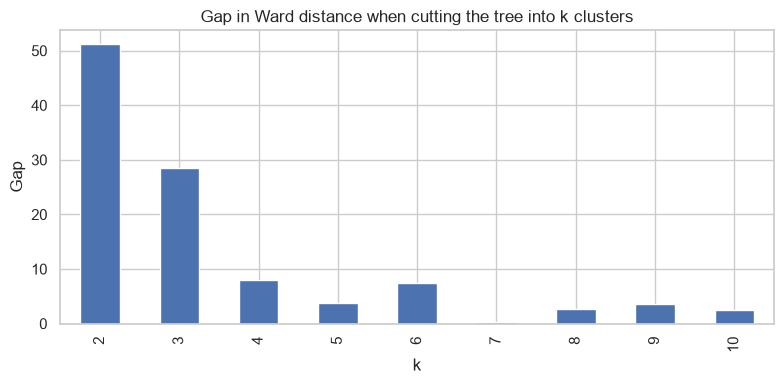

In [18]:
# --- Gap analysis: the largest jump in merge distance suggests the natural k ---
merge_dist = Z[:, 2]
rows = []
for k in range(2, 11):
    lower = merge_dist[-k]          # last merge kept *inside* clusters
    upper = merge_dist[-(k - 1)]    # next merge that would reduce k clusters to k-1
    rows.append({"k": k, "cut_between": f"{lower:.1f} – {upper:.1f}", "gap": upper - lower})
gap_df = pd.DataFrame(rows).set_index("k")
display(gap_df)

fig, ax = plt.subplots(figsize=(8, 4))
gap_df["gap"].plot.bar(ax=ax)
ax.set_title("Gap in Ward distance when cutting the tree into k clusters")
ax.set_ylabel("Gap"); ax.set_xlabel("k")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_dendrogram_gaps.png", dpi=120)
plt.show()

,inertia,silhouette_kmeans,silhouette_hierarchical
k,,,
2,"8,544.62",0.44,0.43
3,"6,332.77",0.35,0.31
4,"4,929.73",0.36,0.28
5,"4,110.44",0.34,0.27
6,"3,566.44",0.33,0.27
7,"3,202.05",0.30,0.27
8,"2,906.17",0.30,0.28
9,"2,669.80",0.29,0.23
10,"2,475.14",0.29,0.22


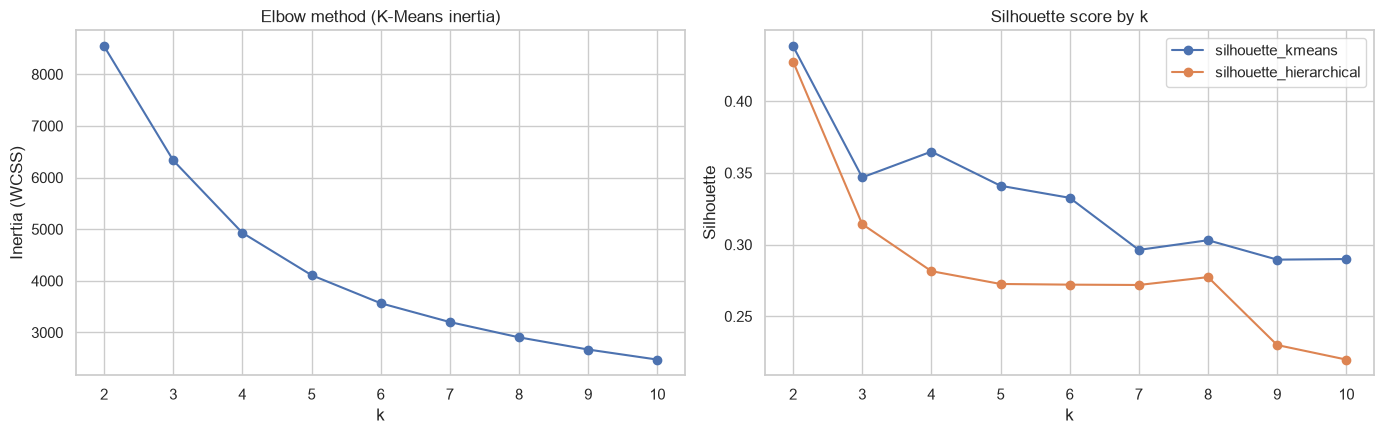

In [19]:
# --- Elbow + Silhouette for k = 2..10 (K-Means and Hierarchical) ---
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    hc_labels = fcluster(Z, k, criterion="maxclust")
    results.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette_kmeans": silhouette_score(X_scaled, km.labels_),
        "silhouette_hierarchical": silhouette_score(X_scaled, hc_labels),
    })
k_eval = pd.DataFrame(results).set_index("k")
display(k_eval.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
k_eval["inertia"].plot(marker="o", ax=axes[0])
axes[0].set_title("Elbow method (K-Means inertia)"); axes[0].set_ylabel("Inertia (WCSS)")
k_eval[["silhouette_kmeans", "silhouette_hierarchical"]].plot(marker="o", ax=axes[1])
axes[1].set_title("Silhouette score by k"); axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_elbow_silhouette.png", dpi=120)
plt.show()

### 5.1 Choosing k – Summary of evidence

Three independent criteria were evaluated for k = 2…10:

| Method | What it measures | Suggested k |
|---|---|---|
| **Dendrogram (Ward)** | Largest gaps in merge distance | 2 (gap 51.2), then 3 (28.5); secondary local gaps at **4 (8.0)** and **6 (7.5)** |
| **Elbow (K-Means inertia)** | Diminishing returns in within-cluster variance | **4–5**: from k=4 on, each additional cluster reduces inertia roughly half as much as the previous one |
| **Silhouette** | Cohesion vs separation of each customer | 2 (0.44), with a **local peak at k=4** (0.365 vs 0.347 at k=3) |

**Interpretation of the silhouette peak at k=4.** Silhouette compares, for each customer, the mean distance to its own
cluster (*a*, cohesion) with the distance to the nearest other cluster (*b*, separation). At k=3, K-Means is forced to merge
two genuinely different groups, so many customers are far from their cluster-mates and the score drops. At k=4 that mixed group
is split, cohesion improves and the score rises. This suggests a **4-group structure is more natural than 3**.

K-Means scores consistently higher than Ward because Ward is a *greedy* algorithm (merges cannot be undone), while K-Means
iteratively reassigns customers to optimize the partition.

**Why not k=2?** It has the best silhouette but only separates active vs inactive customers, which is too coarse to drive
differentiated marketing actions.

**Decision**
- **Primary model: k = 4.** Supported by the silhouette local peak, the elbow region, and a dendrogram gap comparable to k=6.
- **Sensitivity analysis: k = 6.** Supported by a local dendrogram gap; used to check whether a finer split reveals a
  business-relevant segment that k=4 hides.

**Honest caveat.** Silhouette values of 0.30–0.36 indicate a *weak-to-moderate* structure (Kaufman & Rousseeuw: 0.26–0.50).
RFM behavior is a **continuum** rather than well-separated islands. Segments are therefore validated not only with internal
metrics, but also through **agreement between algorithms**, **stability under resampling**, and **business interpretability**
(Sections 6–7).

## 6. Clustering Models: K-Means and Hierarchical (Ward)

Both models are trained on the same input (log1p + standardized RFM) with the selected **k = 4** (primary) and
**k = 6** (sensitivity analysis).

- **K-Means** iteratively assigns each customer to the nearest centroid and recomputes centroids until convergence.
  `n_init=20` runs the algorithm 20 times with different random starts and keeps the best solution.
- **Hierarchical (Ward)** reuses the linkage matrix from Section 5, cutting the tree into k clusters (`fcluster`).

Note: cluster numbers are **arbitrary labels**. Cluster 0 in K-Means is not necessarily cluster 0 in Hierarchical.
Clusters are compared by their **profiles** and by **cross-tabulation**, not by their numbers.

In [21]:
# --- Fit K-Means and Hierarchical for k = 4 (main) and k = 6 (sensitivity) ---
# Input features (X_scaled), one row per customer:
#   Recency   -> days since last purchase       (log1p + standardized)
#   Frequency -> number of distinct invoices    (log1p + standardized)
#   Monetary  -> net revenue in GBP             (log1p + standardized)
from sklearn.metrics import adjusted_rand_score

K_MAIN, K_ALT = 4, 6
labels = pd.DataFrame(index=X_scaled.index)   # one column of cluster labels per model
kmeans_models = {}

for k in [K_MAIN, K_ALT]:
    km = KMeans(
        n_clusters=k,
        algorithm="lloyd",      # classic batch K-Means (scikit-learn default)
        init="k-means++",       # spread-out initial centroids
        n_init=20,              # 20 random restarts, keep the lowest-inertia solution
        random_state=RANDOM_STATE,
    ).fit(X_scaled)
    kmeans_models[k] = km
    labels[f"km{k}"] = km.labels_
    labels[f"hc{k}"] = fcluster(Z, k, criterion="maxclust") - 1   # cut Ward tree into k clusters; labels start at 0

labels.head()

,km4,hc4,km6,hc6
Customer ID,,,,
12346,1,1,1,3
12347,2,0,3,1
12348,0,3,2,5
12349,3,0,3,1
12350,1,1,1,3


In [22]:
# --- Cluster profiles in original RFM units (medians are robust to outliers) ---
def profile(label_col):
    prof = (rfm.join(labels[label_col])
               .groupby(label_col)
               .agg(customers=("Recency", "size"),
                    recency_median=("Recency", "median"),       # days since last purchase
                    frequency_median=("Frequency", "median"),   # number of invoices
                    monetary_median=("Monetary", "median"),     # net GBP spent
                    revenue_total=("Monetary", "sum")))
    prof["pct_customers"] = (prof["customers"] / prof["customers"].sum() * 100).round(1)
    prof["pct_revenue"] = (prof["revenue_total"] / prof["revenue_total"].sum() * 100).round(1)
    return prof.sort_values("monetary_median", ascending=False)

for col in ["km4", "hc4"]:
    print(f"\n=== {col} ===")
    display(profile(col))


=== km4 ===


,customers,recency_median,frequency_median,monetary_median,revenue_total,pct_customers,pct_revenue
km4,,,,,,,
2,1107,15.00,13.00,"5,032.22","11,740,682.86",19.00,71.80
0,1477,158.00,5.00,"1,529.82","2,957,401.13",25.30,18.10
3,1220,23.00,3.00,702.18,"992,200.42",20.90,6.10
1,2028,399.50,1.00,280.82,"671,285.72",34.80,4.10



=== hc4 ===


,customers,recency_median,frequency_median,monetary_median,revenue_total,pct_customers,pct_revenue
hc4,,,,,,,
0,1385,18.00,12.00,"4,304.89","12,636,952.23",23.70,77.20
3,1120,25.00,4.00,"1,045.28","1,496,418.66",19.20,9.10
2,1173,217.00,4.00,970.70,"1,493,744.07",20.10,9.10
1,2154,390.00,1.00,267.08,"734,455.17",36.90,4.50


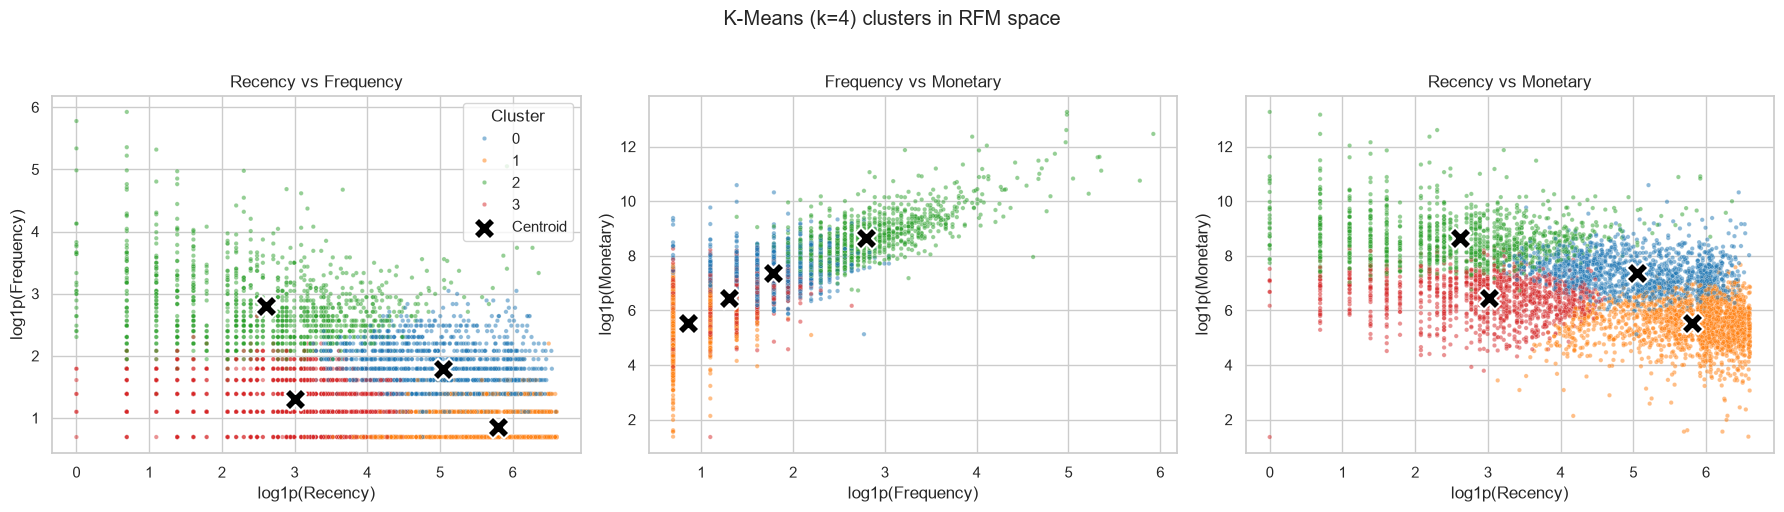

In [23]:
# --- Visualize K-Means k=4 clusters on each pair of RFM variables (log scale) ---
km4 = kmeans_models[K_MAIN]
centroids_log = pd.DataFrame(scaler.inverse_transform(km4.cluster_centers_),
                             columns=rfm.columns)            # centroids back to log1p space

plot_df = rfm_log.join(labels["km4"])
pairs = [("Recency", "Frequency"), ("Frequency", "Monetary"), ("Recency", "Monetary")]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (x, y) in zip(axes, pairs):
    sns.scatterplot(data=plot_df, x=x, y=y, hue="km4", palette="tab10",
                    s=10, alpha=0.5, ax=ax, legend=(ax is axes[0]))
    ax.scatter(centroids_log[x], centroids_log[y], marker="X", s=250,
               c="black", edgecolor="white", linewidth=1.5, label="Centroid")
    ax.set_xlabel(f"log1p({x})"); ax.set_ylabel(f"log1p({y})")
    ax.set_title(f"{x} vs {y}")
axes[0].legend(title="Cluster", loc="best")
plt.suptitle("K-Means (k=4) clusters in RFM space", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "07_kmeans_k4_scatter.png", dpi=120, bbox_inches="tight")
plt.show()

### 6.1 Internal validation metrics

Without labels, cluster quality is measured with **internal metrics**, which only use the data and the cluster assignments:

| Metric | What it measures | Range | Better |
|---|---|---|---|
| **Inertia (WCSS)** | Sum of squared distances from each customer to its cluster centroid (compactness). | ≥ 0 | Lower |
| **Silhouette** | For each customer: (b − a) / max(a, b), where *a* = mean distance to its own cluster and *b* = mean distance to the nearest other cluster. Averaged over all customers. | −1 to 1 | Higher |
| **Davies-Bouldin** | For each cluster, its worst-case ratio (spread_i + spread_j) / distance between centroids, averaged over clusters. Penalizes clusters that are wide and close to each other. | ≥ 0 | Lower |
| **Calinski-Harabasz** | Ratio of between-cluster dispersion to within-cluster dispersion, adjusted for n and k. | ≥ 0 (no upper bound) | Higher |

**Caveats**
- **Inertia always decreases as k grows**, so it cannot compare different k on its own (hence the elbow method).
- All four metrics **favor compact, spherical clusters**, which biases them toward K-Means. That is why we also use
  **agreement between algorithms (ARI)**, **stability** and **business interpretability**.

In [24]:
# --- Internal metrics for each model (K-Means vs Hierarchical, k=4 vs k=6) ---
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

def wcss(X, lbl):
    """Within-cluster sum of squares (inertia) for any labelling: distance of each point to its cluster mean."""
    X = np.asarray(X)
    return sum(((X[lbl == c] - X[lbl == c].mean(axis=0)) ** 2).sum() for c in np.unique(lbl))

metrics_rows = []
for col in ["km4", "hc4", "km6", "hc6"]:
    lbl = labels[col].values
    metrics_rows.append({
        "model": col,
        "algorithm": "K-Means" if col.startswith("km") else "Hierarchical (Ward)",
        "k": int(col[-1]),
        "inertia (↓)": wcss(X_scaled, lbl),
        "silhouette (↑)": silhouette_score(X_scaled, lbl),
        "davies_bouldin (↓)": davies_bouldin_score(X_scaled, lbl),
        "calinski_harabasz (↑)": calinski_harabasz_score(X_scaled, lbl),
    })
metrics_df = pd.DataFrame(metrics_rows).set_index("model")
display(metrics_df.round(3))

,algorithm,k,inertia (↓),silhouette (↑),davies_bouldin (↓),calinski_harabasz (↑)
model,,,,,,
km4,K-Means,4,"4,929.69",0.36,0.94,"4,952.06"
hc4,Hierarchical (Ward),4,"5,596.03",0.28,1.09,"4,131.09"
km6,K-Means,6,"3,565.83",0.33,0.96,"4,551.94"
hc6,Hierarchical (Ward),6,"4,237.94",0.27,1.09,"3,645.23"


### 6.2 Results – K-Means vs Hierarchical (k = 4)

**Both algorithms recover the same four customer archetypes**, organized along two business dimensions:
*how recently* the customer bought (Recency) and *how much value* they bring (Frequency & Monetary).

| Archetype (tentative) | K-Means (cluster) | Hierarchical (cluster) | Profile (K-Means medians) | % customers | % revenue |
|---|---|---|---|---|---|
| **Champions / VIP** | 2 | 0 | R 15 days · F 13 · M £5,032 | 19.0% | **71.8%** |
| **At Risk** | 0 | 2 | R 158 days · F 5 · M £1,530 | 25.3% | 18.1% |
| **New / Promising** | 3 | 3 | R 23 days · F 3 · M £702 | 20.9% | 6.1% |
| **Lost / Hibernating** | 1 | 1 | R 400 days · F 1 · M £281 | 34.8% | 4.1% |

**Key findings**
- **Agreement between algorithms**: two methods with opposite logic (centroid-based vs bottom-up merging) find the same
  four archetypes, which is strong evidence that these groups reflect real structure rather than an algorithmic artifact.
  The main difference: Ward's "Champions" group is larger (1,385 vs 1,107), absorbing some recent mid-value customers.
- **Pareto effect**: 19% of customers (Champions) generate ~72% of net revenue.
- **Continuum, not islands**: the scatter plots show clusters as *segments of a continuum* rather than separated groups,
  consistent with the moderate silhouette (0.36).
- **Model selection**: K-Means k=4 outperforms Hierarchical and k=6 on all internal metrics
  (silhouette 0.36, Davies-Bouldin 0.94, Calinski-Harabasz 4,952). **K-Means k=4 is selected as the main model.**

In [28]:
# --- Final model: K-Means k=4 -> attach cluster label to each customer ---
FINAL_K = 4
final_model = kmeans_models[FINAL_K]
rfm["Cluster"] = labels["km4"]

print(rfm["Cluster"].value_counts().sort_index())
rfm.to_csv(DATA_DIR / "rfm_clusters.csv")   # customer-level table with final cluster, for reuse

Cluster
0    1477
1    2028
2    1107
3    1220
Name: count, dtype: int64


## 7. DBSCAN – Density-based clustering and anomaly detection

**DBSCAN** (Density-Based Spatial Clustering of Applications with Noise) does not need *k*. It groups customers that lie in
**dense regions** and labels isolated customers as **noise (-1)**. It uses two parameters:

- **eps (ε)**: radius of the neighborhood around each customer.
- **min_samples**: minimum number of customers (including itself) within ε for a point to be a **core point**.

Each customer is classified as:
- **Core point**: has ≥ min_samples neighbors within ε.
- **Border point**: within ε of a core point, but not dense enough to be a core point itself.
- **Noise**: neither core nor border → **potential anomaly**.

**Why DBSCAN here?** Unlike K-Means, it does not force every customer into a group. Since our scatter plots suggest a
*continuum* rather than separated groups, we use DBSCAN mainly to:
1. Test whether **density-separated groups** exist at all.
2. **Detect anomalous customers** (noise points) that do not fit the typical behavior.

min_samples = 6 | suggested eps = 0.32 (customer #5,466 of 5,832)


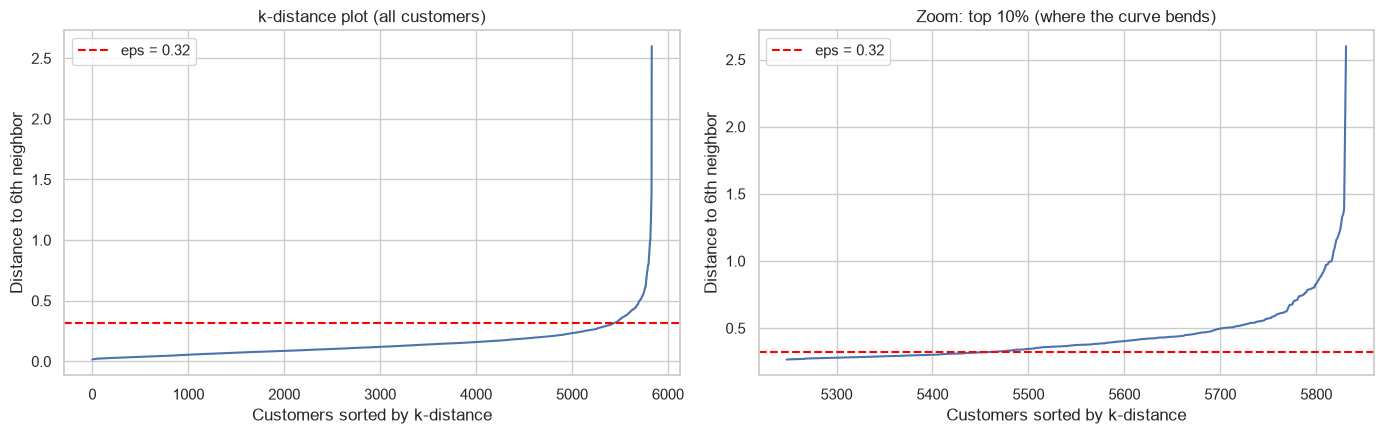

In [29]:
# --- Choose min_samples (rule of thumb) and eps (k-distance plot knee) ---
from sklearn.neighbors import NearestNeighbors

MIN_SAMPLES = 2 * X_scaled.shape[1]          # rule of thumb: 2 x number of features (R, F, M) = 6

# Distance from each customer to its MIN_SAMPLES-th nearest neighbor (the point itself counts as the 1st)
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_dist = np.sort(distances[:, -1])

# Knee detection: point of the normalized curve farthest below the diagonal
x = np.arange(len(k_dist))
x_norm = (x - x.min()) / (x.max() - x.min())
y_norm = (k_dist - k_dist.min()) / (k_dist.max() - k_dist.min())
knee_idx = np.argmax(x_norm - y_norm)
EPS_SUGGESTED = round(float(k_dist[knee_idx]), 2)
print(f"min_samples = {MIN_SAMPLES} | suggested eps = {EPS_SUGGESTED} "
      f"(customer #{knee_idx:,} of {len(k_dist):,})")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, start in zip(axes, [0, int(len(k_dist) * 0.90)]):
    ax.plot(x[start:], k_dist[start:])
    ax.axhline(EPS_SUGGESTED, color="red", linestyle="--", label=f"eps = {EPS_SUGGESTED}")
    ax.set_xlabel("Customers sorted by k-distance"); ax.set_ylabel(f"Distance to {MIN_SAMPLES}th neighbor")
    ax.legend()
axes[0].set_title("k-distance plot (all customers)")
axes[1].set_title("Zoom: top 10% (where the curve bends)")
plt.tight_layout()
plt.savefig(FIG_DIR / "12_dbscan_kdistance.png", dpi=120)
plt.show()

In [30]:
# --- Sensitivity analysis: how results change with eps and min_samples ---
from sklearn.cluster import DBSCAN

grid_rows = []
for eps in np.round(np.linspace(EPS_SUGGESTED * 0.5, EPS_SUGGESTED * 1.5, 5), 2):
    for ms in [MIN_SAMPLES, 10, 20]:
        lbl = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_clusters = len(set(lbl)) - (1 if -1 in lbl else 0)
        noise_mask = lbl == -1
        sil = (silhouette_score(X_scaled[~noise_mask], lbl[~noise_mask])
               if n_clusters > 1 else np.nan)      # silhouette needs >= 2 clusters
        grid_rows.append({"eps": eps, "min_samples": ms, "n_clusters": n_clusters,
                          "n_noise": int(noise_mask.sum()),
                          "pct_noise": round(noise_mask.mean() * 100, 1),
                          "silhouette_no_noise": sil})
dbscan_grid = pd.DataFrame(grid_rows)
display(dbscan_grid.round(3))

,eps,min_samples,n_clusters,n_noise,pct_noise,silhouette_no_noise
0,0.16,6,34,1300,22.30,-0.08
1,0.16,10,29,2051,35.20,0.04
2,0.16,20,13,3536,60.60,0.27
3,0.24,6,13,463,7.90,-0.01
4,0.24,10,8,753,12.90,0.05
5,0.24,20,4,1435,24.60,0.15
6,0.32,6,6,246,4.20,0.08
7,0.32,10,3,334,5.70,0.16
8,0.32,20,3,602,10.30,0.17
9,0.40,6,3,144,2.50,0.18


DBSCAN label counts (-1 = noise):
dbscan
-1     246
 0    3076
 1    1564
 2     924
 3      10
 4       6
 5       6
Name: count, dtype: int64


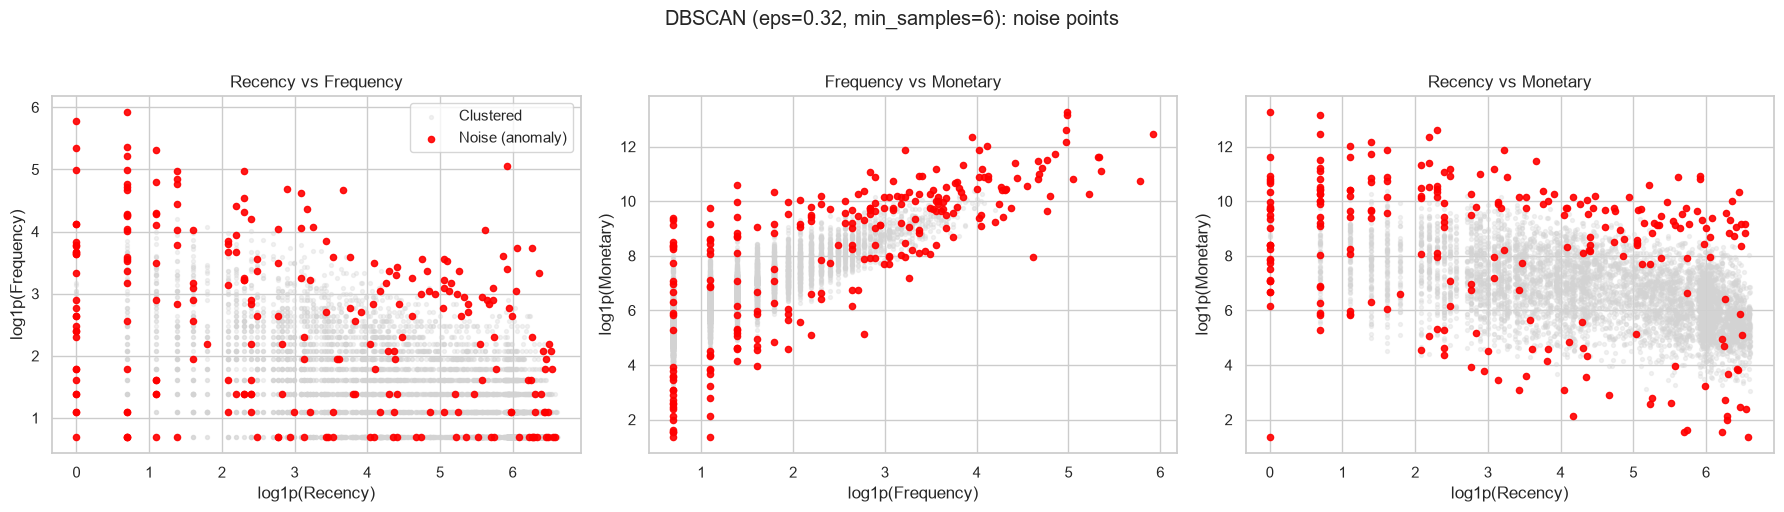

In [31]:
# --- Final DBSCAN model + visualize noise points (potential anomalies) ---
EPS = EPS_SUGGESTED                       # change here if the sensitivity table suggests a better value
dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(X_scaled)
labels["dbscan"] = dbscan.labels_         # -1 = noise

print("DBSCAN label counts (-1 = noise):")
print(labels["dbscan"].value_counts().sort_index())

plot_db = rfm_log.join(labels["dbscan"])
is_noise = plot_db["dbscan"] == -1
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (x_col, y_col) in zip(axes, pairs):
    ax.scatter(plot_db.loc[~is_noise, x_col], plot_db.loc[~is_noise, y_col],
               s=8, alpha=0.3, c="lightgrey", label="Clustered")
    ax.scatter(plot_db.loc[is_noise, x_col], plot_db.loc[is_noise, y_col],
               s=20, alpha=0.9, c="red", label="Noise (anomaly)")
    ax.set_xlabel(f"log1p({x_col})"); ax.set_ylabel(f"log1p({y_col})")
    ax.set_title(f"{x_col} vs {y_col}")
axes[0].legend()
plt.suptitle(f"DBSCAN (eps={EPS}, min_samples={MIN_SAMPLES}): noise points", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "13_dbscan_noise.png", dpi=120, bbox_inches="tight")
plt.show()

In [32]:
# --- Who are the anomalies? Profile, K-Means cluster membership and top customers ---
db = rfm[["Recency", "Frequency", "Monetary"]].join(labels[["dbscan", "km4"]])
db["is_noise"] = db["dbscan"] == -1

noise_profile = db.groupby("is_noise").agg(
    customers=("Recency", "size"),
    recency_median=("Recency", "median"),
    frequency_median=("Frequency", "median"),
    monetary_median=("Monetary", "median"),
    revenue_total=("Monetary", "sum"))
noise_profile["pct_customers"] = (noise_profile["customers"] / len(db) * 100).round(1)
noise_profile["pct_revenue"] = (noise_profile["revenue_total"] / db["Monetary"].sum() * 100).round(1)
display(noise_profile)

print("Noise points by K-Means cluster:")
display(pd.crosstab(db["km4"], db["is_noise"], margins=True))

print("Top 15 anomalous customers by Monetary:")
display(db[db["is_noise"]].sort_values("Monetary", ascending=False).head(15))

,customers,recency_median,frequency_median,monetary_median,revenue_total,pct_customers,pct_revenue
is_noise,,,,,,,
False,5586,100.00,3.00,816.63,"9,991,153.46",95.80,61.10
True,246,21.50,14.00,"9,074.97","6,370,416.67",4.20,38.90


Noise points by K-Means cluster:


is_noise,False,True,All
km4,,,
0,1440,37,1477
1,1998,30,2028
2,971,136,1107
3,1177,43,1220
All,5586,246,5832


Top 15 anomalous customers by Monetary:


,Recency,Frequency,Monetary,dbscan,km4,is_noise
Customer ID,,,,,,
18102,0,145,"578,408.64",-1,2,True
14646,1,145,"523,202.74",-1,2,True
14156,9,144,"297,775.01",-1,2,True
14911,1,373,"258,522.43",-1,2,True
17450,8,51,"233,643.91",-1,2,True
13694,3,143,"190,391.50",-1,2,True
17511,2,60,"168,504.44",-1,2,True
12415,24,24,"143,107.02",-1,2,True
16684,4,55,"141,530.29",-1,2,True


### 7.1 DBSCAN – Results

**1. k-distance plot.** The curve is flat for ~94% of customers and bends gradually (no sharp knee) before rising steeply
for the last ~50 customers. Suggested **eps = 0.32** with **min_samples = 6** (2 × number of features).

**2. Sensitivity analysis.** Results are highly sensitive to the parameters: small eps fragments the data into many
micro-clusters (negative silhouette), while large eps converges to 2 clusters (likely an artifact of Frequency being
discrete: the log gap between 1 and 2 purchases). **No configuration outperforms K-Means** (best silhouette 0.29 vs 0.36).
→ **There are no density-separated customer groups**: customer behavior is a continuum, confirming what the scatter
plots and silhouette scores suggested.

**3. Noise points (eps 0.32): 246 customers (4.2%).** They fall into three groups:
- **Extremely high Frequency & Monetary**: wholesalers / key accounts (real anomalies).
- **Very low Monetary** (£5–£50): marginal customers.
- **Very low Recency** (0–2 days): partly an **artifact of the log1p transform**, which stretches small values and makes
  that region look sparse.

**4. Business finding.** The 246 anomalous customers (4.2%) generate **38.9% of net revenue** (median £9,075 vs £817).
55% of them belong to K-Means cluster 2 (Champions), including the top 15 spenders (£90k–£578k).
→ **The Champions segment is not homogeneous**: it contains a small group of **key accounts** whose scale is an order of
magnitude above the rest. K-Means must assign every customer to a group; DBSCAN isolates them.

**Role of DBSCAN in this project:** not a segmentation model, but a **complementary check** that validates the continuum
structure of customer behavior. The key-account finding is reported as an observation; the final segmentation keeps the
**four K-Means segments**. A dedicated anomaly-detection analysis is out of scope for this project.

## 8. Validation – Are the segments real and useful?

Without ground-truth labels, segment validity is assessed from four complementary angles:

| # | Question | Method |
|---|---|---|
| 1 | Do **different algorithms** find the same groups? | Adjusted Rand Index (ARI) + cross-tab, K-Means vs Hierarchical |
| 2 | Does clustering add value over **simple business rules**? | Cross-tab vs baseline RFM segments |
| 3 | Is **k = 4** the right granularity? | Cross-tab k=4 vs k=6 (which cluster splits?) |
| 4 | Are segments **stable** if the data changes? | Bootstrap: refit on 80% subsamples, compare with the full-data solution (ARI + per-cluster Jaccard) |

Internal metrics (silhouette, Davies-Bouldin, Calinski-Harabasz) were already reported in Section 6.1,
and DBSCAN (Section 7) showed that the data is a continuum without density-separated groups.

In [33]:
# --- Tentative segment names (final names decided in Section 9) ---
SEGMENT_NAMES = {2: "Champions", 0: "At Risk", 3: "New/Promising", 1: "Lost"}
SEGMENT_ORDER = ["Champions", "At Risk", "New/Promising", "Lost"]
labels["km4_name"] = labels["km4"].map(SEGMENT_NAMES)
labels["km4_name"].value_counts()

km4_name
Lost             2028
At Risk          1477
New/Promising    1220
Champions        1107
Name: count, dtype: int64

,ARI
K-Means k=4 vs Hierarchical k=4,0.59
K-Means k=6 vs Hierarchical k=6,0.52


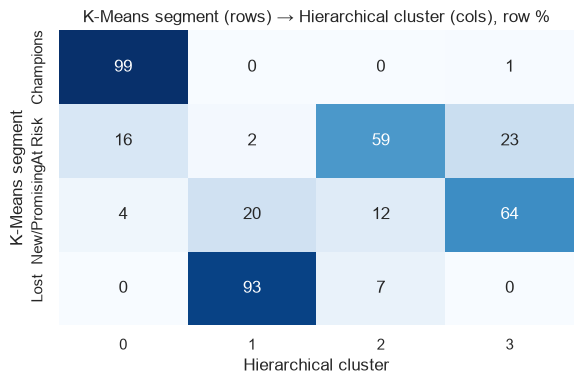

In [34]:
# --- Validation 1: agreement between K-Means and Hierarchical (k=4) ---
ari_algos = pd.Series({
    "K-Means k=4 vs Hierarchical k=4": adjusted_rand_score(labels["km4"], labels["hc4"]),
    "K-Means k=6 vs Hierarchical k=6": adjusted_rand_score(labels["km6"], labels["hc6"]),
}).round(3).to_frame("ARI")
display(ari_algos)

# Row % : where did each K-Means segment's customers go in the Hierarchical solution?
ct_algo = pd.crosstab(labels["km4_name"], labels["hc4"], normalize="index").mul(100).reindex(SEGMENT_ORDER)
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(ct_algo, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar=False)
ax.set_title("K-Means segment (rows) → Hierarchical cluster (cols), row %")
ax.set_xlabel("Hierarchical cluster"); ax.set_ylabel("K-Means segment")
plt.tight_layout()
plt.savefig(FIG_DIR / "14_val_kmeans_vs_hierarchical.png", dpi=120)
plt.show()

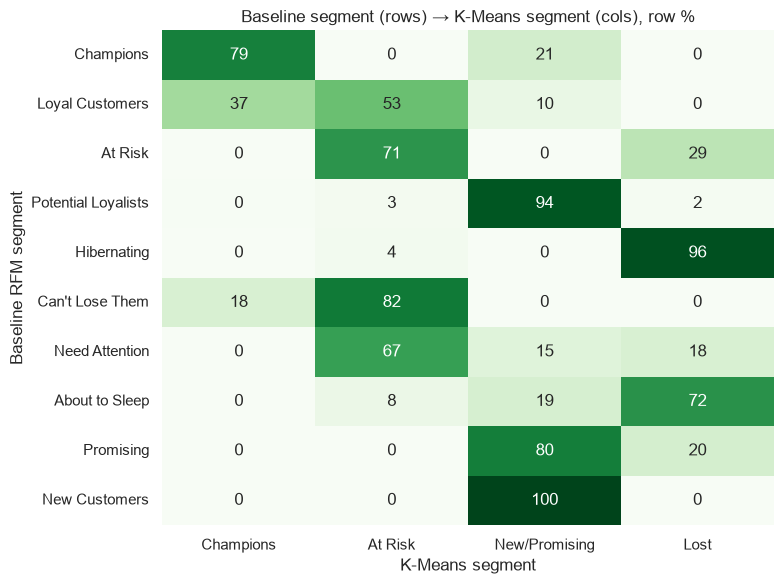

ARI baseline vs K-Means k=4: 0.443


In [35]:
# --- Validation 2: rule-based baseline (10 segments) vs K-Means (4 segments), row % ---
ct_base = (pd.crosstab(base["Segment"], labels["km4_name"], normalize="index")
             .mul(100)[SEGMENT_ORDER])
ct_base = ct_base.loc[baseline_summary.index]         # same order as baseline table (by revenue)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(ct_base, annot=True, fmt=".0f", cmap="Greens", ax=ax, cbar=False)
ax.set_title("Baseline segment (rows) → K-Means segment (cols), row %")
ax.set_xlabel("K-Means segment"); ax.set_ylabel("Baseline RFM segment")
plt.tight_layout()
plt.savefig(FIG_DIR / "15_val_baseline_vs_kmeans.png", dpi=120)
plt.show()

print("ARI baseline vs K-Means k=4:", round(adjusted_rand_score(base["Segment"], labels["km4"]), 3))

,customers,recency_median,frequency_median,monetary_median,revenue_total,pct_customers,pct_revenue
km6,,,,,,,
5,425,8.00,24.00,"9,719.13","8,665,984.39",7.30,53.00
2,933,60.00,9.00,"3,175.10","3,831,337.08",16.00,23.40
3,699,10.00,6.00,"1,724.87","1,464,250.14",12.00,8.90
4,1278,283.50,3.00,952.94,"1,491,651.63",21.90,9.10
0,997,36.00,2.00,460.68,"539,739.03",17.10,3.30
1,1500,421.00,1.00,222.06,"368,607.86",25.70,2.30


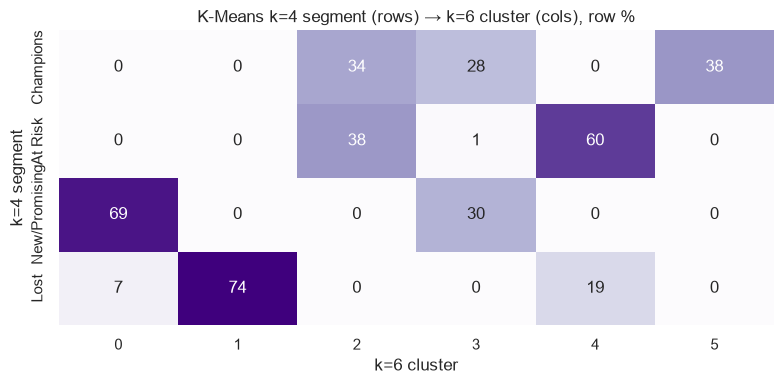

In [36]:
# --- Validation 3: how do the 4 segments split when k = 6? ---
display(profile("km6"))
ct_46 = pd.crosstab(labels["km4_name"], labels["km6"], normalize="index").mul(100).reindex(SEGMENT_ORDER)
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(ct_46, annot=True, fmt=".0f", cmap="Purples", ax=ax, cbar=False)
ax.set_title("K-Means k=4 segment (rows) → k=6 cluster (cols), row %")
ax.set_xlabel("k=6 cluster"); ax.set_ylabel("k=4 segment")
plt.tight_layout()
plt.savefig(FIG_DIR / "16_val_k4_vs_k6.png", dpi=120)
plt.show()

### 8.4 Stability – Subsampling

**Idea:** if the segments are real, they should not depend on *which* customers happen to be in the dataset
(analogous to cross-validation in supervised learning). We repeat 50 times:
1. Draw a random **80% subsample** of customers (without replacement).
2. Refit K-Means on the subsample.
3. Use it to **predict the segment of all customers**, and compare with the full-data reference solution.

Two scores are reported:
- **ARI (global stability)**: agreement of the whole partition with the reference (1 = identical).
- **Jaccard per segment (local stability)**: a segment is a *set of customers* (each customer is in it or not), so it
  can be compared with the Jaccard similarity between sets: |A ∩ B| / |A ∪ B|. Since cluster numbers are arbitrary across
  runs, each reference segment is matched with the bootstrap cluster of **highest** Jaccard.
  Rule of thumb (Hennig, 2007): **> 0.85 highly stable**, 0.75–0.85 stable, 0.60–0.75 weak pattern, **< 0.50 dissolved**.

The same procedure is run for k = 3…6 to check whether **k = 4 is also a stable choice**.

,mean,std,min
k,,,
3,0.98,0.02,0.94
4,0.95,0.03,0.88
5,0.95,0.05,0.81
6,0.89,0.08,0.73


,mean,std,min
Champions,0.96,0.03,0.91
At Risk,0.94,0.05,0.84
New/Promising,0.98,0.01,0.96
Lost,0.98,0.02,0.94


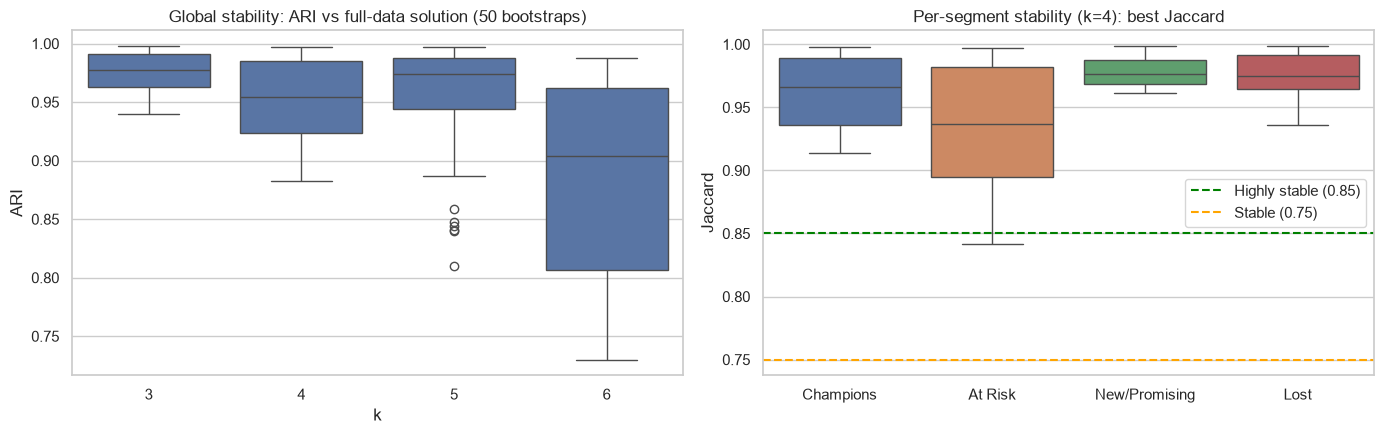

In [37]:
# --- Validation 4: bootstrap stability (global ARI for k=3..6, per-cluster Jaccard for k=4) ---
N_BOOT, FRAC = 50, 0.8
rng = np.random.RandomState(RANDOM_STATE)

def best_jaccard_per_cluster(ref, pred):
    """For each reference cluster, the highest Jaccard overlap with any predicted cluster."""
    out = {}
    for c in np.unique(ref):
        a = ref == c
        out[c] = max((a & (pred == d)).sum() / (a | (pred == d)).sum() for d in np.unique(pred))
    return out

stab_rows, jacc_rows = [], []
for k in [3, 4, 5, 6]:
    ref = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
    if k == K_MAIN:
        ref = labels["km4"].values                       # use the exact final model as reference
    for b in range(N_BOOT):
        idx = rng.choice(len(X_scaled), size=int(FRAC * len(X_scaled)), replace=False)
        km_b = KMeans(n_clusters=k, n_init=10, random_state=b).fit(X_scaled.iloc[idx])
        pred = km_b.predict(X_scaled)                    # predict ALL customers
        stab_rows.append({"k": k, "boot": b, "ARI": adjusted_rand_score(ref, pred)})
        if k == K_MAIN:
            jacc_rows.append(best_jaccard_per_cluster(ref, pred))

stab = pd.DataFrame(stab_rows)
display(stab.groupby("k")["ARI"].agg(["mean", "std", "min"]).round(3))

jacc = pd.DataFrame(jacc_rows).rename(columns=SEGMENT_NAMES)[SEGMENT_ORDER]
display(jacc.agg(["mean", "std", "min"]).T.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=stab, x="k", y="ARI", ax=axes[0])
axes[0].set_title("Global stability: ARI vs full-data solution (50 bootstraps)")
sns.boxplot(data=jacc, ax=axes[1])
axes[1].axhline(0.85, color="green", linestyle="--", label="Highly stable (0.85)")
axes[1].axhline(0.75, color="orange", linestyle="--", label="Stable (0.75)")
axes[1].set_title("Per-segment stability (k=4): best Jaccard")
axes[1].set_ylabel("Jaccard"); axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "17_val_stability.png", dpi=120)
plt.show()

### 8.5 Validation – Summary of results

| # | Test | Result | Verdict |
|---|---|---|---|
| 1 | **K-Means vs Hierarchical** | ARI = 0.59 (k=4) vs 0.52 (k=6). Champions (99%) and Lost (93%) are almost identical across algorithms; New/Promising (64%) and At Risk (59%) share their core but differ at the borders. | ✅ Same archetypes recovered by two different algorithms |
| 2 | **K-Means vs baseline RFM rules** | ARI = 0.44. Each baseline segment maps mainly to one K-Means segment (10 → 4). K-Means **splits "Loyal Customers"** (37% Champions / 53% At Risk) and is stricter with Champions (21% of baseline Champions → New/Promising). | ✅ Simpler and adds information the rules miss |
| 3 | **k=4 vs k=6** | k=6 splits Champions into three groups (incl. a top group of 425 customers with 53% of revenue) and creates mixed clusters crossing business boundaries. | ✅ k=4 is the more actionable granularity |
| 4 | **Stability (subsampling, 50 runs)** | Global ARI: k=4 mean 0.95 (min 0.88) vs k=6 mean 0.89 (min 0.73). Per-segment Jaccard ≥ 0.94 for all four segments (Hennig: > 0.85 = highly stable). | ✅ All four segments are highly stable |

**Overall conclusion.** The four segments are **real and useful**, not an artifact of the algorithm:
- They are recovered by **two algorithms with opposite logic**.
- They remain **stable under resampling**.
- They **simplify and refine** the rule-based segmentation.

**Weak point – At Risk.** It is consistently the least crisp segment (lowest agreement with Hierarchical, 59%, and lowest
Jaccard, min 0.84). It is the *middle* segment of the continuum, bordering Champions (customers slowing down) and
New/Promising. Its border customers are analyzed in Section 9.

**Recurring observation – Key accounts.** DBSCAN (Section 7) and k=6 independently isolate a small top group inside
Champions (~5–7% of customers, ~40–50% of revenue). It is reported as an observation; the final model keeps four segments.

## 9. Interpretation – From clusters to business segments

With the four segments validated (Section 8), this section answers the business question:
*What types of customers does the store have, and which commercial action fits each one?*

1. **Final profile** of each segment (size, RFM behavior, revenue contribution, average order value).
2. **Business names and recommended actions.**
3. **Border customers**: customers that sit between two segments (low silhouette), with a focus on *At Risk*,
   the least crisp segment identified in the validation.

In [40]:
# --- Final segment profile (business view) ---
seg = rfm[["Recency", "Frequency", "Monetary"]].join(labels["km4_name"].rename("Segment"))
seg["AOV"] = seg["Monetary"] / seg["Frequency"]          # Average Order Value (aov): Monetary / Frequency per purchase

final_profile = (seg.groupby("Segment")
                    .agg(customers=("Recency", "size"),
                         recency_median=("Recency", "median"),
                         frequency_median=("Frequency", "median"),
                         monetary_median=("Monetary", "median"),
                         aov_median=("AOV", "median"),
                         revenue_total=("Monetary", "sum"))
                    .reindex(SEGMENT_ORDER))
final_profile["% customers"] = (final_profile["customers"] / final_profile["customers"].sum() * 100).round(1)
final_profile["% revenue"] = (final_profile["revenue_total"] / final_profile["revenue_total"].sum() * 100).round(1)
final_profile["revenue_per_customer"] = (final_profile["revenue_total"] / final_profile["customers"]).round(0)
display(final_profile)

,customers,recency_median,frequency_median,monetary_median,aov_median,revenue_total,% customers,% revenue,revenue_per_customer
Segment,,,,,,,,,
Champions,1107,15.00,13.00,"5,032.22",358.15,"11,740,682.86",19.00,71.80,"10,606.00"
At Risk,1477,158.00,5.00,"1,529.82",310.79,"2,957,401.13",25.30,18.10,"2,002.00"
New/Promising,1220,23.00,3.00,702.18,247.02,"992,200.42",20.90,6.10,813.00
Lost,2028,399.50,1.00,280.82,201.08,"671,285.72",34.80,4.10,331.00


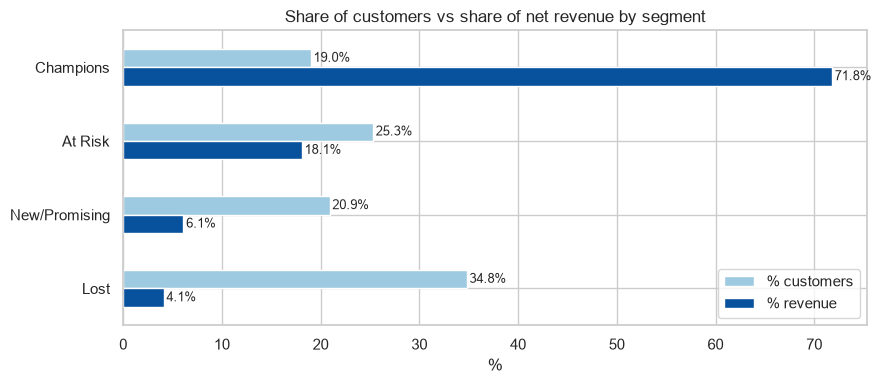

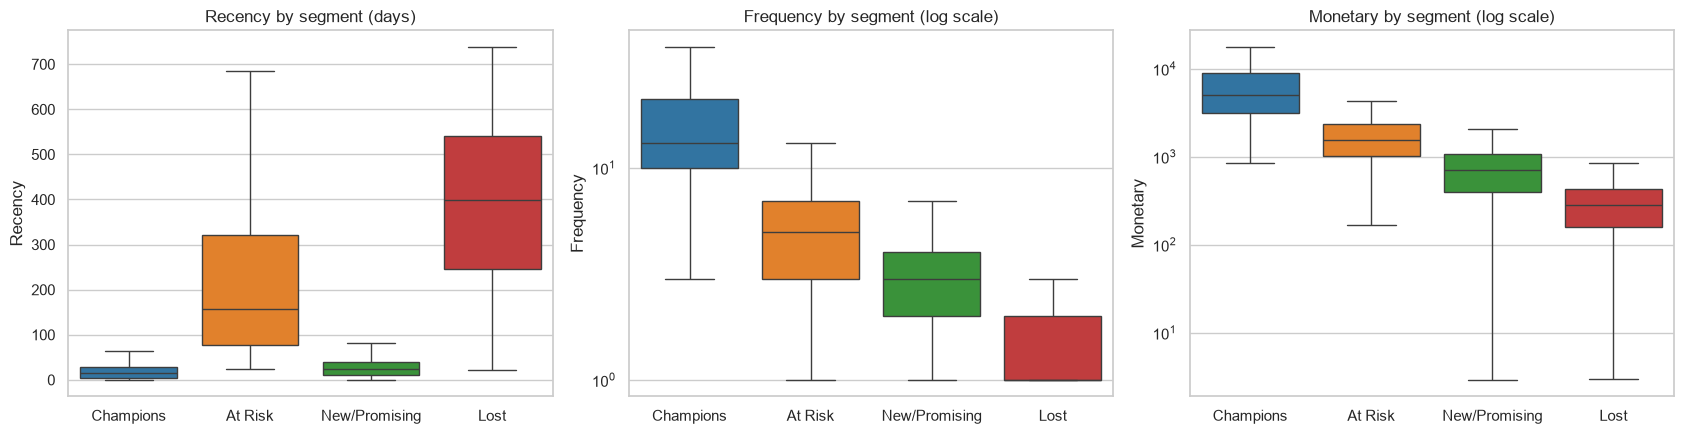

In [42]:
# --- Visual summary: Pareto (customers vs revenue) + RFM distributions per segment ---
palette = dict(zip(SEGMENT_ORDER, sns.color_palette("tab10", 4)))

fig, ax = plt.subplots(figsize=(9, 4))
final_profile[["% customers", "% revenue"]].plot.barh(ax=ax, color=["#9ecae1", "#08519c"])
ax.set_title("Share of customers vs share of net revenue by segment")
ax.set_xlabel("%"); ax.set_ylabel(""); ax.invert_yaxis()
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", fontsize=9, padding=2)
plt.tight_layout()
plt.savefig(FIG_DIR / "18_segments_pareto.png", dpi=120)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.boxplot(data=seg, x="Segment", y=col, order=SEGMENT_ORDER, palette=palette,
                hue="Segment", legend=False, showfliers=False, ax=ax)
    if col != "Recency":
        ax.set_yscale("log")
    ax.set_title(f"{col} by segment" + (" (log scale)" if col != "Recency" else " (days)"))
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "19_segments_rfm_boxplots.png", dpi=120)
plt.show()

### 9.1 Segments and recommended actions

| Segment | Who they are | Customers | Revenue | Revenue / customer | Recommended action |
|---|---|---|---|---|---|
| 🏆 **Champions** | Bought very recently (median 15 days), buy often (13 orders) and spend the most (median £5,032; AOV £358). | 19.0% | **71.8%** | £10,606 | **Retain & reward**: loyalty program, early access to new products, dedicated account management for the top spenders. Avoid generic discounts: they already buy at full price. |
| ⚠️ **At Risk** | Used to buy regularly (5 orders, £1,530; AOV £311) but have not purchased for ~5 months (median 158 days). Highly heterogeneous in Recency (IQR ≈ 80–320 days). | 25.3% | 18.1% | £2,002 | **Win back**: personalized reactivation campaigns, "we miss you" offers based on past purchases, satisfaction survey to detect the reason for churn. Prioritize those who stopped most recently (Section 9.2). |
| 🌱 **New/Promising** | Recent customers (median 23 days) with few purchases (3) and low spend so far (£702; AOV £247). | 20.9% | 6.1% | £813 | **Nurture & convert**: onboarding sequence, product recommendations and incentives for the *next* purchase. The goal is to increase **purchase frequency**, the main driver of value. |
| 💤 **Lost** | One purchase (median) more than a year ago (400 days), low spend (£281; AOV £201). | 34.8% | 4.1% | £331 | **Low-cost reactivation or let go**: occasional mass campaigns only (e.g., seasonal sales). Not worth individual investment. |

*AOV = Average Order Value (Monetary / Frequency), median per segment.*

**Key business insights**
- **Strong Pareto effect:** 19% of customers (Champions) generate ~72% of net revenue. One Champion is worth about
  **32 Lost customers** (£10,606 vs £331). Within Champions, the mean doubles the median, reflecting a small group of
  key accounts (see Section 7).
- **Value is driven by frequency, not basket size:** AOV varies only 1.8× across segments (£201–£358), while total
  Monetary varies 18× (£281–£5,032). Champions do not spend much more *per order*; they order *much more often*.
  Actions should focus on **increasing purchase frequency**.
- **At Risk is the priority for retention:** 25% of customers and 18% of revenue, with a proven purchase history.
  Recovering them is cheaper than acquiring new customers.
- **New/Promising is the growth pipeline:** their Recency is similar to Champions; what separates them is Frequency.
  Their future value depends on turning a first or second purchase into a habit.
- **Seasonality matters:** revenue peaks in Oct–Nov (Section 1). Reactivation campaigns for At Risk and Lost
  should be timed before that season.

,silhouette_mean,pct_border,pct_negative
Segment,,,
Champions,0.33,14.30,5.20
At Risk,0.31,11.20,1.40
New/Promising,0.28,18.50,2.80
Lost,0.47,4.80,0.00


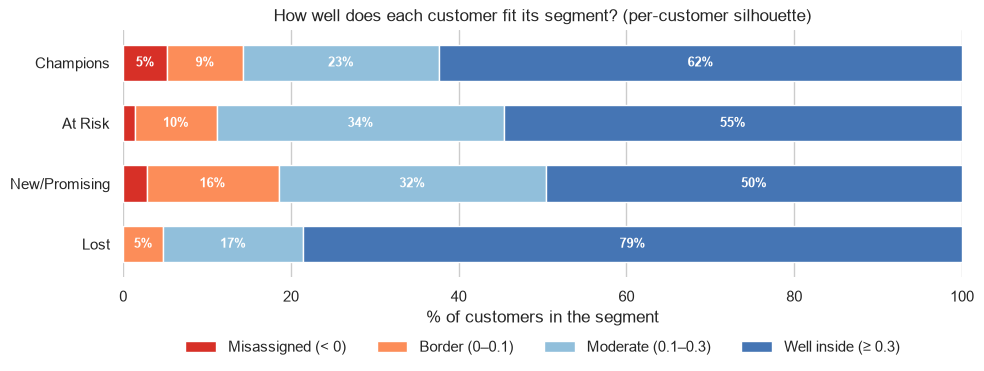

Border customers: own segment (rows) vs second-closest segment (cols)


second_segment,At Risk,Champions,Lost,New/Promising
Segment,,,,
Champions,111,0,0,47
At Risk,0,24,92,50
New/Promising,119,21,86,0
Lost,61,0,0,36


In [45]:
# --- Border customers: per-customer silhouette + second-closest segment ---
from sklearn.metrics import silhouette_samples

BORDER_THRESHOLD = 0.1
sil_values = silhouette_samples(X_scaled, labels["km4"])
dist_to_centroids = final_model.transform(X_scaled)               # distance to each of the 4 centroids
second_closest = np.argsort(dist_to_centroids, axis=1)[:, 1]

border = pd.DataFrame({
    "Segment": labels["km4_name"].values,
    "silhouette": sil_values,
    "second_segment": pd.Series(second_closest).map(SEGMENT_NAMES).values,
}, index=X_scaled.index)
border["is_border"] = border["silhouette"] < BORDER_THRESHOLD

# Summary per segment
sil_summary = border.groupby("Segment").agg(
    silhouette_mean=("silhouette", "mean"),
    pct_border=("is_border", lambda s: round(s.mean() * 100, 1)),
    pct_negative=("silhouette", lambda s: round((s < 0).mean() * 100, 1)),
).reindex(SEGMENT_ORDER)
display(sil_summary.round(3))

# Silhouette bands per segment (100% stacked bars)
bins = [-1, 0, BORDER_THRESHOLD, 0.3, 1]
band_labels = ["Misassigned (< 0)", f"Border (0–{BORDER_THRESHOLD})", "Moderate (0.1–0.3)", "Well inside (≥ 0.3)"]
border["sil_band"] = pd.cut(border["silhouette"], bins=bins, labels=band_labels, right=False)

band_pct = (pd.crosstab(border["Segment"], border["sil_band"], normalize="index")
              .mul(100).reindex(SEGMENT_ORDER)[band_labels])

fig, ax = plt.subplots(figsize=(10, 4))
band_pct.plot.barh(stacked=True, color=["#d73027", "#fc8d59", "#91bfdb", "#4575b4"], width=0.6, ax=ax)
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:.0f}%" if v >= 4 else "" for v in container.datavalues],
                 label_type="center", fontsize=9, color="white", fontweight="bold")
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% of customers in the segment"); ax.set_ylabel("")
ax.set_title("How well does each customer fit its segment? (per-customer silhouette)")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
ax.grid(axis="y", visible=False)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.savefig(FIG_DIR / "20_silhouette_bands.png", dpi=120)
plt.show()

# Where do border customers lean towards?
print("Border customers: own segment (rows) vs second-closest segment (cols)")
display(pd.crosstab(border.loc[border["is_border"], "Segment"],
                    border.loc[border["is_border"], "second_segment"]).reindex(SEGMENT_ORDER))

In [46]:
# --- Focus: At Risk border customers, split by the segment they lean towards ---
at_risk_border = (border[(border["Segment"] == "At Risk") & border["is_border"]]
                  .join(seg[["Recency", "Frequency", "Monetary", "AOV"]]))

at_risk_split = at_risk_border.groupby("second_segment").agg(
    customers=("Recency", "size"),
    recency_median=("Recency", "median"),
    frequency_median=("Frequency", "median"),
    monetary_median=("Monetary", "median"),
    revenue_total=("Monetary", "sum"),
)
print(f"At Risk customers: {(border['Segment'] == 'At Risk').sum():,} | "
      f"border (silhouette < {BORDER_THRESHOLD}): {len(at_risk_border):,}")
display(at_risk_split)

At Risk customers: 1,477 | border (silhouette < 0.1): 166


,customers,recency_median,frequency_median,monetary_median,revenue_total
second_segment,,,,,
Champions,24,40.50,9.00,"4,350.43","132,586.88"
Lost,92,367.00,3.00,780.34,"81,040.05"
New/Promising,50,55.50,4.00,"1,216.24","68,432.58"


### 9.2 Border customers

**How well does each customer fit its segment?** (per-customer silhouette)

| Segment | Well inside (≥ 0.3) | Border or misassigned (< 0.1) | Reading |
|---|---|---|---|
| Lost | 79% | 5% | Most solid segment: "one purchase over a year ago" is an unmistakable profile |
| Champions | 62% | 14% (5% negative) | Solid core with a tail of lower-frequency customers resembling At Risk |
| At Risk | 55% | 11% | Intermediate |
| New/Promising | 50% | 19% | Fuzziest at the individual level: customers with 1–2 purchases differ from Lost mainly by Recency |

**Segment neighborhood.** Border customers reveal how segments are arranged along the RFM continuum:
**Champions and Lost never border each other** (0 border customers), while At Risk borders all other three segments, acting as the
*center* of the continuum. This explains why At Risk was the least stable segment in the validation (Section 8).

*Note:* stability (Section 8) and per-customer silhouette answer different questions. New/Promising is highly reproducible as a set
(Jaccard 0.98) but has a wide fringe of individually ambiguous customers; At Risk has fewer ambiguous customers, but its borders shift
between runs.

**Inside At Risk: three different situations** (166 border customers out of 1,477)

| Leaning towards | Customers | Recency (median) | Frequency (median) | Monetary (median) | Total revenue | Business reading |
|---|---|---|---|---|---|---|
| Champions | 24 | 40 days | 9 | £4,350 | £132,587 | **Valuable customers who just slowed down → top priority** |
| New/Promising | 50 | 55 days | 4 | £1,216 | £68,433 | Mid-value customers who recently cooled down |
| Lost | 92 | 367 days | 3 | £780 | £81,040 | Practically lost |

**Actionable finding: an early-warning list.** 24 customers with a near-Champion profile (9 orders, median £4,350) have not purchased
for only ~40 days. Contacting them now is far cheaper than trying to win them back months later. Border analysis turns a static
segmentation into a **prioritized action list**.

## 10. Conclusions

### Business question
*What types of customers does the store have, and which commercial action fits each one?*

The store's 5,832 customers fall into **four behavioral segments** along two dimensions: *how recently* they buy and
*how much value* they bring:

| Segment | % customers | % revenue | Action |
|---|---|---|---|
| 🏆 Champions | 19.0% | 71.8% | Retain & reward |
| ⚠️ At Risk | 25.3% | 18.1% | Win back (prioritize recent slowdowns) |
| 🌱 New/Promising | 20.9% | 6.1% | Nurture & increase purchase frequency |
| 💤 Lost | 34.8% | 4.1% | Low-cost mass campaigns only |

**Main insights:** a strong Pareto effect (19% → 72% of revenue); value is driven by **purchase frequency**, not basket size;
and border analysis produces an **early-warning list** of high-value customers who just slowed down.

### Are the segments real? (the unsupervised validation challenge)
- **Choice of k = 4** supported by the dendrogram, the elbow method and a silhouette local peak.
- **Two algorithms with opposite logic** (K-Means and Ward) recover the same four archetypes (ARI = 0.59; extremes ≥ 93% agreement).
- **Highly stable**: mean ARI 0.95 over 50 subsamples; all segments with Jaccard ≥ 0.94.
- **Adds value over rule-based RFM**: simplifies 10 segments into 4 and detects that half of the "Loyal Customers" are already cooling down.
- **DBSCAN** found no density-separated groups, confirming that customer behavior is a **continuum**: the segments are useful
  *partitions* of that continuum rather than natural islands, which is consistent with a moderate silhouette (0.36).

### Limitations
- **22.8% of transactions lack a Customer ID** and were excluded.
- **Static snapshot**: segments are computed at one reference date (2011-12-10). Customers move between segments over time.
- **Cancellations** of orders placed before Dec 2009 cannot be matched to their original purchase.
- **Retail and wholesale customers are mixed**: a small group of key accounts dominates the Champions segment (Sections 7 and 8).
- The **log1p transform** improves K-Means but creates artificially sparse regions (e.g., very recent customers) that DBSCAN flags as noise.

### Next steps
- **Temporal validation**: recompute segments at different reference dates and track transitions (e.g., Champions → At Risk).
- **Additional features**: product categories, tenure (days since first purchase), country, returns rate.
- **Measure impact**: A/B test the recommended actions per segment.
- **Anomaly detection** on key accounts (covered in a later project).